In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
clothing_customers = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/Data-Science-for-Marketing-Analytics-Second-Edition/refs/heads/master/Chapter03/Datasets/Clothing_Customers.csv')

In [3]:
clothing_customers.head()

,income,age,days_since_purchase,annual_spend
0,37453,48,504,4441
1,50775,50,566,4239
2,71047,41,326,5834
3,52239,52,259,5456
4,112343,27,279,1749


In [4]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['income', 'age', 'days_since_purchase', 'annual_spend']

scaler = StandardScaler()

cc_scaled = clothing_customers.copy()

cc_scaled[cols_to_scale] = scaler.fit_transform(cc_scaled[cols_to_scale])

In [5]:
cc_scaled.head()

,income,age,days_since_purchase,annual_spend
0,-0.890426,0.604861,0.753257,0.062276
1,-0.553094,0.789354,1.306361,-0.058939
2,-0.039778,-0.040865,-0.834688,0.898182
3,-0.516023,0.973847,-1.432398,0.671353
4,1.005897,-1.332317,-1.253977,-1.553129


In [6]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)

pca_res = pca.fit_transform(cc_scaled[cols_to_scale])

cc_scaled['pc1'] = pca_res[:,0]
cc_scaled['pc2'] = pca_res[:,1]


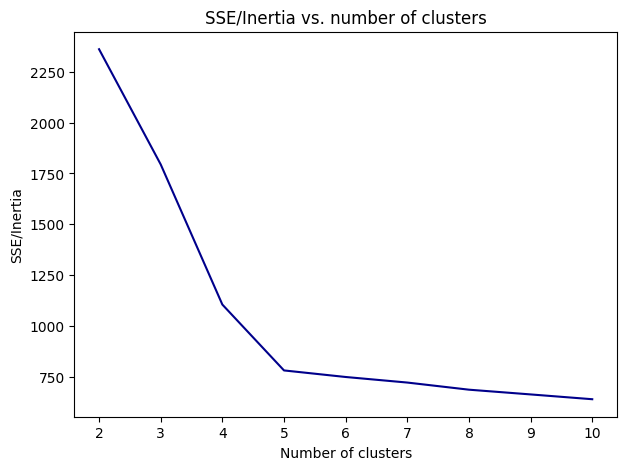

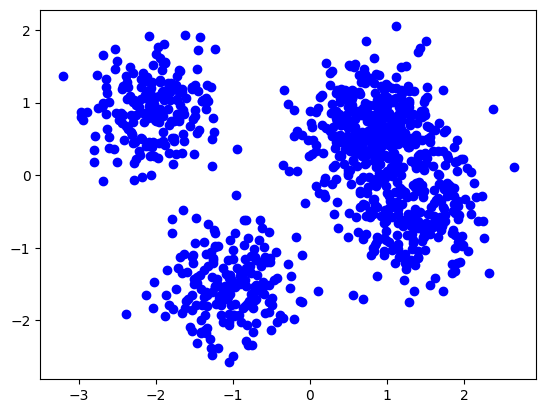

In [7]:
from sklearn.cluster import KMeans

X = cc_scaled[cols_to_scale]

inertia_scores = []

for K in range(2,11):
    inertia = KMeans(n_clusters=K, random_state=42).fit(X).inertia_
    inertia_scores.append(inertia)
    
plt.figure(figsize=[7,5])
plt.plot(range(2,11), inertia_scores, color='darkblue')
plt.title("SSE/Inertia vs. number of clusters")
plt.xlabel("Number of clusters")
plt.ylabel("SSE/Inertia")
plt.show()

plt.scatter(cc_scaled.pc1, cc_scaled.pc2, color='blue')
plt.show()